# Bregman proximal point minimization

Let $f$ and $h$ be closed, proper, convex and differentiable on the relevant domain in a real finite-dimensional Euclidean space. Let $x_\star$ minimize $f$, $\alpha>0$, $R\geq0$, and integer $N\geq1$. Assume all updates and evaluations are well-defined. Define
$$D_h(u,v)=h(u)-h(v)-\langle\nabla h(v),u-v\rangle.$$
The initial condition is $D_h(x_\star,x_0)\leq R$ (the radius is not squared). The update and its optimality equation are
$$x_{k+1}\in\operatorname*{argmin}_x\{\alpha f(x)+D_h(x,x_k)\},\qquad
\nabla h(x_{k+1})=\nabla h(x_k)-\alpha\nabla f(x_{k+1}),\quad 0\leq k<N.$$
The performance metric is $f(x_N)-f(x_\star)$. The supplied conjecture is $R/(\alpha N)$.

The PEP uses convex interpolation for both functions, providing an outer relaxation of the differentiable problem class. No extra curvature assumption is introduced.


## Proof Statement

### Theorem

Under the stated assumptions, for any $\alpha>0$, $R\geq0$ and integer $N\geq1$, define
$$V_{k}=\frac{\alpha k\bigl(f(x_{k})-f(x_{\star})\bigr)+D_h(x_{\star},x_{k})-D_h(x_{\star},x_{0})}{\alpha N},
\qquad 0\leq k\leq N.$$
Then $V_{0}=0$ and $V_{k+1}\leq V_{k}$. Consequently,
$$\boxed{f(x_{N})-f(x_{\star})\leq\frac{R}{\alpha N}.}$$
Equivalently, the unnormalized energy $\mathcal E_{k}=\alpha k(f(x_{k})-f(x_{\star}))+D_h(x_{\star},x_{k})$ is nonincreasing, with $\mathcal E_{0}\leq R$.


### Proof outline

Write $f_i=f(x_i)$, $h_i=h(x_i)$, $g_i=\nabla f(x_i)$, $q_i=\nabla h(x_i)$, and
$$r^f_{i,j}=f_j-f_i+\langle g_j,x_i-x_j\rangle\leq0,\qquad
r^h_{i,j}=h_j-h_i+\langle q_j,x_i-x_j\rangle\leq0.$$
These signs follow directly from convexity. The proximal optimality equation is $q_{k+1}=q_k-\alpha g_{k+1}$.
For the displayed potential
$$V_{k}=\frac{\alpha k(f_k-f_{\star})+D_h(x_{\star},x_k)-D_h(x_{\star},x_0)}{\alpha N},$$
the initial step satisfies
$$V_1-V_0=\frac1N r^f_{\star,1}+\frac1{\alpha N}r^h_{1,0}\leq0,\qquad V_0=0.$$
For every $1\leq k<N$, the exact decrease identity is
$$V_{k+1}-V_k=
\frac1N r^f_{\star,k+1}+\frac{k}{N}r^f_{k,k+1}
+\frac{k+1}{\alpha N}r^h_{k+1,k}+\frac{k}{\alpha N}r^h_{k,k+1}\leq0.$$
There are no additional residual families or square terms. All four multipliers are nonnegative because $\alpha>0$, $N\geq1$, and $k\geq1$. Thus $V_N\leq V_0=0$.

Finally, $r^h_{\star,N}=-D_h(x_{\star},x_N)\leq0$, and the exact terminal identity is
$$f_N-f_{\star}-\frac{R}{\alpha N}
=V_N+\frac{D_h(x_{\star},x_0)-R+r^h_{\star,N}}{\alpha N}\leq V_N\leq0.$$
The initial condition gives the sign of $D_h(x_{\star},x_0)-R$. This proves the rate with $R$, not $R^2$. When $N=1$, the separate initial-step identity and terminal identity suffice. No strict convexity of $h$, strong convexity, or bounded Euclidean radius is used.


In [1]:
from pathlib import Path
import sys
import json

notebook_dir = Path.cwd().resolve()
repo_root = notebook_dir / 'supplementary' / 'approved'
REPO_ROOT = repo_root
sys.path[:0] = [str(repo_root), str(notebook_dir / 'supplementary' / 'helpers')]

In [2]:
from runtime import OWNED_HELPER
import pepflow as pf
import matplotlib.pyplot as plt
import numpy as np

assert OWNED_HELPER
assert Path(pf.__file__).resolve().is_relative_to(repo_root)
print('Framework:', pf.__file__)

Framework: C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\bppm\r05\supplementary\approved\pepflow\__init__.py


## Function and parameter definitions

Both functions use the approved convex interpolation API. The Bregman expression below uses its stated orientation.

In [3]:
f = pf.ConvexFunction(is_basis=True, tags=["f"])
h = pf.ConvexFunction(is_basis=True, tags=["h"])
alpha = pf.Parameter("alpha")
R = pf.Parameter("R")


def bregman(u, v):
    return h(u) - h(v) - h.grad(v) * (u - v)

## Algorithm and PEP setup

In [4]:
def make_ctx_bppm(ctx_name: str, N, stepsize) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    f.set_stationary_point("x_star")
    for k in range(int(N)):
        x = f.bregman_prox(x, stepsize, h, tag=f"x_{k + 1}")
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_bppm(f"ctx_{N}", N, alpha)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        bregman(ctx["x_star"], ctx["x_0"]).le(R, name="initial_condition")
    )
    pb.set_performance_metric(f(ctx[f"x_{N}"]) - f(ctx["x_star"]))
    return ctx, pb, f

In [5]:
ctx, pb, objective = get_pep_setup(4, {'alpha': 1, 'R': 1})
print('Initial certificate horizon:', 4)
print('Tagged terminal iterate:', ctx['x_4'])

Initial certificate horizon: 4
Tagged terminal iterate: x_4


## Numerical evidence

One sweep, $N=1,\ldots,7$, with $\alpha=R=1$, using CLARABEL defaults. The saved results are reused here without repeating the sweep.

N=1: PEP=0.9999999998, conjecture=1.0000000000, status=optimal
N=2: PEP=0.4999999982, conjecture=0.5000000000, status=optimal
N=3: PEP=0.3333333297, conjecture=0.3333333333, status=optimal
N=4: PEP=0.2499999997, conjecture=0.2500000000, status=optimal
N=5: PEP=0.1999999969, conjecture=0.2000000000, status=optimal
N=6: PEP=0.1666666662, conjecture=0.1666666667, status=optimal
N=7: PEP=0.1428571412, conjecture=0.1428571429, status=optimal
Inverse values: [1.         2.00000001 3.00000003 4.00000001 5.00000008 6.00000002
 7.00000008]
Inverse differences: [1.00000001 1.00000003 0.99999997 1.00000007 0.99999994 1.00000007]
Maximum absolute discrepancy: 3.6219285903804632e-09


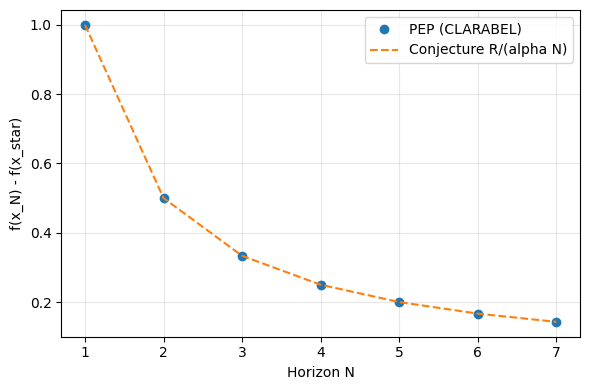

In [6]:
state = json.loads((notebook_dir / 'state' / 'bppm_b1.json').read_text())
rows = state['sweep_results']
for row in rows:
    print(f"N={row['N']}: PEP={row['opt_value']:.10f}, conjecture={row['conjectured']:.10f}, status={row['attempts'][-1]['status']}")
values = np.array([row['opt_value'] for row in rows])
horizons = np.array([row['N'] for row in rows])
print('Inverse values:', 1 / values)
print('Inverse differences:', np.diff(1 / values))
print('Maximum absolute discrepancy:', max(row['absolute_error'] for row in rows))
assert np.max(np.abs(values - 1 / horizons)) < 1e-5
plt.figure(figsize=(6, 4))
plt.plot(horizons, values, 'o', label='PEP (CLARABEL)')
plt.plot(horizons, 1 / horizons, '--', label='Conjecture R/(alpha N)')
plt.xlabel('Horizon N')
plt.ylabel('f(x_N) - f(x_star)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The computed values match the supplied conjecture $R/(\alpha N)$ for the tested normalization. The inverse values grow by approximately one at every step. Parameter scaling and the all-horizon guarantee remain proof obligations.

## Full-PEP certificate

We retain one coherent primal-dual certificate from the sparse solve at $N=4$, $\alpha=R=1$. The dense solve and sparse solve are stored separately; all sparse multipliers, the Gram remainder, and the bound originate in the same sparse solve. The frozen numerical tolerances are unchanged.

The dense solution has optimizer comparisons for $f$, forward comparisons among iterates for $f$, and adjacent/forward comparisons for $h$. Its Gram remainder has eigenvalues below $4\cdot10^{-10}$. We test a nearest-neighbor relaxation preserving the optimizer comparisons. CLARABEL defaults are used for both solves.


In [7]:
import hashlib
import sympy as sp
from certificate_tools import inventory, scalar_from_gram, certificate_id

dense = json.loads((notebook_dir / 'state/bppm_dense.json').read_text())
b2 = json.loads((notebook_dir / 'state/bppm_b2.json').read_text())
assert certificate_id(b2) == b2['certificate_id']
for path, expected in b2['certificate_provenance']['source_hashes'].items():
    assert hashlib.sha256((notebook_dir / path).read_bytes()).hexdigest() == expected
N = b2['N_verify']
params = {key: sp.S(value) for key, value in json.loads(b2['params_json']).items()}
print('Dense bound:', dense['opt_value'])
print('Dense basis:', dense['basis_vectors'])
print('Dense S eigenvalues:', np.linalg.eigvalsh(np.array(dense['S_matrix'])))
for owner in ('f', 'h'):
    active = {name: value for name, value in dense['named_dual_values'].items() if name.startswith(owner + ':') and value is not None and abs(value) > 1e-6}
    print('Dense active', owner, active)

Dense bound:

 0.249999999673264
Dense basis: ['x_0', 'x_star', 'x_1', 'grad_f(x_1)', 'grad_h(x_0)', 'x_2', 'grad_f(x_2)', 'x_3', 'grad_f(x_3)', 'x_4', 'grad_f(x_4)', 'grad_h(x_star)']
Dense S eigenvalues: [7.96853300e-11 9.89586246e-11 1.22556895e-10 1.66551014e-10
 2.06075328e-10 2.32616479e-10 2.32616584e-10 2.59157367e-10
 2.98682337e-10 3.42676601e-10 3.66275376e-10 3.85547976e-10]
Dense active f {'f:x_star,x_1': 0.2500000001689168, 'f:x_star,x_2': 0.2500000004016963, 'f:x_star,x_3': 0.25000000047968607, 'f:x_star,x_4': 0.250000000624397, 'f:x_1,x_2': 0.1369405681700336, 'f:x_1,x_3': 0.07321261054556437, 'f:x_1,x_4': 0.03984682136016044, 'f:x_2,x_3': 0.25273758087457177, 'f:x_2,x_4': 0.1342029879166301, 'f:x_3,x_4': 0.5759501909772722}
Dense active h {'h:x_1,x_0': 0.24999999971102999, 'h:x_1,x_2': 0.063727957934551, 'h:x_1,x_3': 0.03336578927728938, 'h:x_1,x_4': 0.039846821401737224, 'h:x_2,x_1': 0.3869405679419204, 'h:x_2,x_3': 0.1185345933147731, 'h:x_2,x_4': 0.13420298789083407, 'h:x_3,x_2':

In [8]:
keep = {'initial_condition', f'h:x_star,x_{N}'}
keep.update(f'f:x_star,x_{i}' for i in range(1, N+1))
keep.update(f'f:x_{i},x_{i+1}' for i in range(1, N))
keep.update(f'h:x_{i},x_{i-1}' for i in range(1, N+1))
keep.update(f'h:x_{i},x_{i+1}' for i in range(1, N))
relaxed = [c.name for c, *_ in inventory(ctx, pb) if c.name not in keep]
assert relaxed == b2['relaxed_constraints']
pb.set_relaxed_constraints(relaxed)
print('Dropped constraints:', len(relaxed))
print('Sparse bound:', b2['opt_value'])
print('Dense/sparse discrepancy:', abs(dense['opt_value'] - b2['opt_value']))
assert abs(dense['opt_value'] - b2['opt_value']) < 1e-5
for name, value in b2['named_dual_values'].items():
    if value is not None:
        print(name, value)

Dropped constraints: 35
Sparse bound: 0.24999999998895409
Dense/sparse discrepancy: 3.1569008518417263e-10
initial_condition 0.250000000194885
f:x_star,x_1 0.25000000017685203
f:x_star,x_2 0.25000000028344505
f:x_star,x_3 0.25000000025593727
f:x_star,x_4 0.2500000001735796
f:x_1,x_2 0.2500000001768519
f:x_2,x_3 0.5000000002378435
f:x_3,x_4 0.7500000002713274
h:x_1,x_0 0.25000000019488505
h:x_1,x_2 0.25000000013443113
h:x_2,x_1 0.5000000001068626
h:x_2,x_3 0.5000000003342693
h:x_3,x_2 0.7500000003067007
h:x_3,x_4 0.7500000002243119
h:x_4,x_3 1.0000000001967435
h:x_star,x_4 0.25000000019488483


### Initial formula search

Inspecting the sparse values suggests the following candidate multipliers (all omitted terms are zero):
$$\tau=\frac1{\alpha N},\quad
\lambda^f_{\star,i}=\frac1N\ (1\leq i\leq N),\quad
\lambda^f_{i,i+1}=\frac{i}{N}\ (1\leq i<N),$$
$$\lambda^h_{i,i-1}=\frac{i}{\alpha N}\ (1\leq i\leq N),\quad
\lambda^h_{i,i+1}=\frac{i}{\alpha N}\ (1\leq i<N),\quad
\lambda^h_{\star,N}=\frac1{\alpha N},\qquad S_{\rm guess}=0.$$
Here $\lambda^f_{i,j}$ multiplies $f(x_j)-f(x_i)+\langle\nabla f(x_j),x_i-x_j\rangle\leq0$, and similarly for $h$.
These are numerical candidates, not yet an arbitrary-horizon full-PEP proof. No target-specific reference was consulted. The checks below compare all active multipliers, not just the returned $f$ group.


In [9]:
def candidate_multipliers(N, alpha):
    values = {'initial_condition': 1/(alpha*N), f'h:x_star,x_{N}': 1/(alpha*N)}
    values.update({f'f:x_star,x_{i}': 1/N for i in range(1, N+1)})
    values.update({f'f:x_{i},x_{i+1}': i/N for i in range(1, N)})
    values.update({f'h:x_{i},x_{i-1}': i/(alpha*N) for i in range(1, N+1)})
    values.update({f'h:x_{i},x_{i+1}': i/(alpha*N) for i in range(1, N)})
    return values

candidate = candidate_multipliers(sp.Integer(N), params['alpha'])
errors = [abs(float(candidate.get(name, 0)) - value) for name, value in b2['named_dual_values'].items() if value is not None]
print('Maximum candidate multiplier error:', max(errors))
assert max(errors) < 1e-4
for owner, groups in b2['all_lambda_groups'].items():
    for group_name, display in groups.items():
        labels = display['row_names']
        columns = display['col_names']
        matrix = np.array([[candidate.get(f'{owner}:{r},{c}', sp.S.Zero) for c in columns] for r in labels], dtype=object)
        print('Candidate multipliers:', owner, group_name)
        pf.pprint_labeled_matrix(pf.MatrixWithNames(matrix, labels, columns))

Maximum candidate multiplier error: 3.34269278923216e-10
Candidate multipliers: f convex


<IPython.core.display.Math object>

Candidate multipliers: h convex


<IPython.core.display.Math object>

### Selected Gram remainder and decomposition

The spectral decomposition below retains every eigenvalue of the selected $S$; no numerical term is discarded. With factor-coordinate rows $E$, $S=E^TDE$ and $S_{\rm numeric}=\sum_{ij}D_{ij}\ell_i\ell_j$. All eigenvalues are nonnegative within the frozen PSD tolerance. The separate zero candidate matches $S$ within $10^{-4}$; it does not replace the saved numerical remainder.


In [10]:
S_array = np.asarray(b2['S_matrix'], dtype=float)
D = np.asarray(b2['numerical_decomposition']['D'], dtype=float)
E = np.asarray(b2['numerical_decomposition']['ell_coords'], dtype=float)
print('Selected S eigenvalues / diagonal D:', np.diag(D))
print('S factor reconstruction error:', np.max(np.abs(E.T @ D @ E - S_array)))
assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
print('S=0 candidate error:', np.max(np.abs(S_array)))
assert np.max(np.abs(S_array)) < 1e-4
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.zeros_like(S_array), b2['S_row_names'], b2['S_col_names']))
print('Selected numerical S (retained, not rounded to zero):')
pf.pprint_labeled_matrix(pf.MatrixWithNames(S_array, b2['S_row_names'], b2['S_col_names']))

Selected S eigenvalues / diagonal D: [9.28515042e-11 1.60776742e-10 1.75347014e-10 1.86972248e-10
 1.92505548e-10 1.92505569e-10 1.92505571e-10 1.92505593e-10
 1.98038865e-10 2.09664092e-10 2.24234369e-10 2.92159639e-10]
S factor reconstruction error: 2.8836072065850606e-25
S=0 candidate error: 1.925055854508916e-10


<IPython.core.display.Math object>

Selected numerical S (retained, not rounded to zero):


<IPython.core.display.Math object>

### Complete numerical certificate verification

Every inequality residual is oriented as $r_c\leq0$. The checked identity includes the initial-condition constant:
$$[f(x_N)-f(x_\star)]-\mathrm{bound}-\sum_c d_c r_c+S_{\rm numeric}=0.$$
The next cell checks Gram coordinates, function coordinates, offset, dual signs, PSD, decomposition reconstruction, and dense/sparse agreement. All scalar and matrix families must be inventoried; this setup has only scalar interpolation constraints and the Gram PSD constraint.


In [11]:
def verify_certificate(ctx, pb, params, data, dense_value):
    ctx.set_as_current()
    pm = pf.ExpressionManager(ctx, resolve_parameters=params)
    basis = ctx.basis_vectors()
    assert [str(v) for v in basis] == data["basis_vectors"]
    assert [str(v) for v in ctx.basis_scalars()] == data["basis_scalars"]
    entries = inventory(ctx, pb)
    assert {c.name for c, *_ in entries} == set(data["named_dual_values"]) == set(data["constraint_metadata"])
    weighted = pf.Scalar.zero()
    duals = []
    for c, origin, owner, group in entries:
        meta = data["constraint_metadata"][c.name]
        assert (meta["origin"], meta["owner"], meta["group"], meta["comparator"]) == (origin, owner, group, c.cmp.value)
        v = data["named_dual_values"][c.name]
        if meta["relaxed"]:
            assert v is None and c.name in data["relaxed_constraints"]
            continue
        assert v is not None
        residual = c.lhs - c.rhs
        if c.cmp == pf.Comparator.GE:
            residual = -residual
        weighted += float(v) * (pf.Scalar.zero() + residual)
        if c.cmp != pf.Comparator.EQ:
            duals.append(float(v))
    S = np.asarray(data["S_matrix"], dtype=float)
    S_numeric = scalar_from_gram(ctx, S)
    diff = pb.performance_metric - data["opt_value"] - weighted + S_numeric
    checked = pm.eval_scalar(diff)
    def max_abs(a):
        return float(np.max(np.abs(np.asarray(a, dtype=float)), initial=0.0))
    D = np.asarray(data["numerical_decomposition"]["D"], dtype=float)
    E = np.asarray(data["numerical_decomposition"]["ell_coords"], dtype=float)
    residuals = {"identity_gram_max_abs": max_abs(checked.inner_prod_coords),
                 "identity_func_max_abs": max_abs(checked.func_coords),
                 "identity_offset_abs": max_abs(checked.offset),
                 "S_reconstruction_max_abs": max_abs(E.T @ D @ E - S),
                 "dense_relaxed_gap": abs(data["opt_value"] - dense_value),
                 "minimum_scalar_inequality_dual": min(duals, default=0),
                 "minimum_S_eigenvalue": float(np.linalg.eigvalsh((S + S.T) / 2).min()),
                 "minimum_matrix_inequality_eigenvalue": 0.0}
    tolerances = dict(identity_atol=1e-5, identity_rtol=0, reconstruction_atol=1e-4,
                      reconstruction_rtol=1e-5, dual_tol=1e-6, psd_tol=1e-6, dense_opt_atol=1e-5)
    passed = (data["certificate_provenance"]["solver_status"] == "optimal"
              and np.all(np.isfinite(S)) and np.allclose(S, S.T, atol=1e-6, rtol=0)
              and max(residuals[k] for k in ("identity_gram_max_abs", "identity_func_max_abs", "identity_offset_abs")) <= 1e-5
              and np.allclose(E.T @ D @ E, S, atol=1e-4, rtol=1e-5)
              and residuals["dense_relaxed_gap"] < 1e-5
              and residuals["minimum_scalar_inequality_dual"] >= -1e-6
              and residuals["minimum_S_eigenvalue"] >= -1e-6)
    return {"tolerances": tolerances, "residuals": residuals, "passed": bool(passed)}, checked

In [12]:
checks, residual = verify_certificate(ctx, pb, params, b2, dense['opt_value'])
print('Numerical checks:', checks)
assert checks['passed']
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(residual.inner_prod_coords, dtype=float), b2['basis_vectors'], b2['basis_vectors']))
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(residual.func_coords, dtype=float).reshape(1, -1), ['function residual'], b2['basis_scalars']))
print('Offset residual:', residual.offset)
exact_weighted = pf.Scalar.zero()
for constraint, *_ in inventory(ctx, pb):
    coefficient = candidate.get(constraint.name, sp.S.Zero)
    exact_weighted += coefficient * (pf.Scalar.zero() + constraint.lhs - constraint.rhs)
exact_diff = pb.performance_metric - params['R']/(params['alpha']*N) - exact_weighted
exact_coords = pf.ExpressionManager(ctx, resolve_parameters=params).eval_scalar(exact_diff)
assert all(sp.simplify(v) == 0 for v in np.asarray(exact_coords.inner_prod_coords).flat)
assert all(sp.simplify(v) == 0 for v in np.asarray(exact_coords.func_coords).flat)
assert sp.simplify(exact_coords.offset) == 0
print('Candidate exact identity at N=4: all coordinates zero. This is a fixed-horizon check.')

Numerical checks:

 {'tolerances': {'identity_atol': 1e-05, 'identity_rtol': 0, 'reconstruction_atol': 0.0001, 'reconstruction_rtol': 1e-05, 'dual_tol': 1e-06, 'psd_tol': 1e-06, 'dense_opt_atol': 1e-05}, 'residuals': {'identity_gram_max_abs': 1.925055854508916e-10, 'identity_func_max_abs': 8.89814000260003e-10, 'identity_offset_abs': 2.0593091121234863e-10, 'S_reconstruction_max_abs': 2.8836072065850606e-25, 'dense_relaxed_gap': 3.1569008518417263e-10, 'minimum_scalar_inequality_dual': 0.25000000013443113, 'minimum_S_eigenvalue': 9.285150418730221e-11, 'minimum_matrix_inequality_eigenvalue': 0.0}, 'passed': True}


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Offset residual: 2.05930911212349e-10
Candidate exact identity at N=4: all coordinates zero. This is a fixed-horizon check.


### Block 2 conclusion

The selected numerical certificate is verified. Candidate formulas match all active groups, and the zero Gram candidate passes an exact fixed-horizon identity check. The initial closed-form search is complete; the arbitrary-horizon identity remains unresolved. Status: `numerical_certificate_verified=True`, `analytic_full_pep_verified=False`, `lyapunov_proof_verified=False`. Blocks 3–5 remain to be done.

### Additional horizon certificate (B2 revisit)

A fresh dense and sparse solve at N=6 used the same setup, normalization and relaxation recipe. The complete N=6 certificate is separate from the selected N=4 certificate. The following cell rechecks its full numerical identity before B3 uses it. No new rank observation is made here.

In [13]:
b2_n6 = json.loads((notebook_dir / 'supplementary/bppm_N6_b2.json').read_text())
assert certificate_id(b2_n6) == b2_n6['certificate_id']
for path, expected in b2_n6['certificate_provenance']['source_hashes'].items():
    assert hashlib.sha256((notebook_dir / path).read_bytes()).hexdigest() == expected
ctx6, pb6, obj6 = get_pep_setup(6, params)
pb6.set_relaxed_constraints(b2_n6['relaxed_constraints'])
checks6, residual6 = verify_certificate(ctx6, pb6, params, b2_n6, b2_n6['dense_opt_value'])
assert checks6['passed']
print('N=6 complete-certificate residuals:', checks6['residuals'])
print('N=6 candidate multiplier discrepancy:', b2_n6['candidate_lambda_max_error'])
print('N=6 candidate S discrepancy:', b2_n6['candidate_S_max_error'])
ctx.set_as_current()

N=6 complete-certificate residuals: {'identity_gram_max_abs': 5.137577413019937e-10, 'identity_func_max_abs': 3.5859586411390865e-09, 'identity_offset_abs': 7.146743197239402e-10, 'S_reconstruction_max_abs': 1.34416849539867e-24, 'dense_relaxed_gap': 2.526807096892014e-10, 'minimum_scalar_inequality_dual': 0.16666666705238128, 'minimum_S_eigenvalue': 2.9477517848782846e-10, 'minimum_matrix_inequality_eigenvalue': 0.0}
N=6 candidate multiplier discrepancy: 8.254828209874887e-10
N=6 candidate S discrepancy: 5.137577413019937e-10


## Lyapunov partial sums

Let $r^f_{i,j}=f(x_j)-f(x_i)+\langle\nabla f(x_j),x_i-x_j\rangle\leq0$ and define $r^h_{i,j}$ similarly. The numerical partial sum starts at $V_0=0$. At each step it accumulates the saved weighted terms
$$V_{k+1}-V_k=d^f_{\star,k+1}r^f_{\star,k+1}
+d^f_{k,k+1}r^f_{k,k+1}
+d^h_{k+1,k}r^h_{k+1,k}
+d^h_{k,k+1}r^h_{k,k+1},$$
where the second and fourth terms are absent for $k=0$. All coefficients are nonnegative, giving the required nonincreasing direction. The complete $S$ is retained as one PSD boundary piece, together with $d^h_{\star,N}r^h_{\star,N}$. There are no omitted contributions.

The selected trial uses $N=4$. The same recipe is independently checked at $N=6$. Rank agreement is finite-sample discovery evidence; it does not yet prove an arbitrary-horizon theorem.


In [14]:
certificate = b2
N_int = N
params_sp = params
REPO_ROOT = repo_root

In [15]:
"""Revalidate selected certificate, then expose all weighted contributions."""
assert certificate_id(certificate) == certificate['certificate_id']
assert certificate['closed_form_search']['completed']
assert certificate['certificate_provenance']['pep_type'] == 'primal'
assert N_int == certificate['N_verify']
assert params_sp == {key: sp.S(value) for key, value in json.loads(certificate['params_json']).items()}
for path, expected in certificate['certificate_provenance']['source_hashes'].items():
    assert hashlib.sha256((notebook_dir / path).read_bytes()).hexdigest() == expected
assert Path(pf.__file__).resolve().is_relative_to(REPO_ROOT)
assert set(pb.relaxed_constraints) == set(certificate['relaxed_constraints'])
assert certificate['S_row_names'] == certificate['S_col_names'] == [str(v) for v in ctx.basis_vectors()]
assert certificate['normalization']['tau_name'] == certificate['tau_name'] == 'initial_condition'
assert certificate['tau_sol'] == certificate['named_dual_values']['initial_condition']
assert certificate['normalization']['bound_value'] == certificate['opt_value']
assert certificate['normalization']['initial_condition'] == 'D_h(x_star,x_0) <= R'
assert certificate['normalization']['performance_metric'] == 'f(x_N)-f(x_star)'
checks, certificate_residual = verify_certificate(ctx, pb, params_sp, certificate, certificate['dense_opt_value'])
assert checks['passed']
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
basis = list(ctx.basis_vectors())
S_array = np.asarray(certificate['S_matrix'], dtype=float)
S_scalar = scalar_from_gram(ctx, S_array)
weighted_terms = {}
interpolation_terms = {}
extra_duals = {}
saved_duals = certificate['named_dual_values']
tau_name = certificate['tau_name']
for constraint, origin, owner, group in inventory(ctx, pb):
    meta = certificate['constraint_metadata'][constraint.name]
    assert meta['kind'] == 'scalar' and meta['shape'] == []
    assert meta['relaxed'] == (constraint.name in pb.relaxed_constraints)
    value = saved_duals[constraint.name]
    if meta['relaxed']:
        assert value is None
        continue
    assert value is not None and np.isfinite(value)
    assert constraint.cmp == pf.Comparator.LE
    assert value >= -1e-6
    contribution = value * (pf.Scalar.zero() + constraint.lhs - constraint.rhs)
    weighted_terms[constraint.name] = contribution
    if origin == 'interpolation':
        interpolation_terms[constraint.name] = contribution
    elif constraint.name != tau_name:
        extra_duals[constraint.name] = value
assert not extra_duals
certificate_checked = True
tol = certificate['numerical_checks']['tolerances']
print('Saved certificate revalidated:', checks['residuals'])


Saved certificate revalidated: {'identity_gram_max_abs': 1.925055854508916e-10, 'identity_func_max_abs': 8.89814000260003e-10, 'identity_offset_abs': 2.0593091121234863e-10, 'S_reconstruction_max_abs': 2.8836072065850606e-25, 'dense_relaxed_gap': 3.1569008518417263e-10, 'minimum_scalar_inequality_dual': 0.25000000013443113, 'minimum_S_eigenvalue': 9.285150418730221e-11, 'minimum_matrix_inequality_eigenvalue': 0.0}


In [16]:
"""Retain the complete numerical S as one PSD boundary piece."""
D = np.asarray(certificate['numerical_decomposition']['D'], dtype=float)
E = np.asarray(certificate['numerical_decomposition']['ell_coords'], dtype=float)
assert certificate['numerical_decomposition']['basis_labels'] == [str(v) for v in basis]
assert np.all(np.diag(D) >= -1e-6)
assert np.allclose(E.T @ D @ E, S_array, atol=1e-4, rtol=1e-5)
S_piece_terms = {'full_S': S_scalar}
S_assignment = {'full_S': 'boundary'}
assert np.linalg.eigvalsh((S_array + S_array.T)/2).min() >= -1e-6


In [17]:
"""Adjacent-index partial sums; all increments are nonpositive."""
grouping_checked = False
rank_tolerance = 1e-4
rank_left, rank_right = 1, 1
group_terms = {name: term for name, term in weighted_terms.items() if name != tau_name}
term_assignment = {}
for name in group_terms:
    if name == f'h:x_star,x_{N_int}':
        term_assignment[name] = 'boundary'
    else:
        owner, pair = name.split(':')
        first, second = pair.split(',')
        if owner == 'f' and first == 'x_star':
            term_assignment[name] = int(second.split('_')[1]) - 1
        else:
            i, j = int(first.split('_')[1]), int(second.split('_')[1])
            assert abs(i-j) == 1
            term_assignment[name] = max(i, j) - 1
assert set(term_assignment) == set(group_terms)
assert set(S_assignment) == set(S_piece_terms)
assert all(step in set(range(N_int)) | {'boundary'} for step in term_assignment.values())

# Positive inequality weights and subtracted PSD pieces ensure V_{k+1} <= V_k.
lyap = [pf.Scalar.zero()]
partial_sum = pf.Scalar.zero()
for step in range(N_int):
    partial_sum += sum((group_terms[name] for name, target in term_assignment.items()
                        if target == step), pf.Scalar.zero())
    partial_sum -= sum((S_piece_terms[name] for name, target in S_assignment.items()
                        if target == step), pf.Scalar.zero())
    lyap.append(partial_sum)
ranks = []
singular_values = []
for k, Vk in enumerate(lyap):
    matrix = np.asarray(pm.eval_scalar(Vk).inner_prod_coords, dtype=float)
    singular_values.append(np.linalg.svd(matrix, compute_uv=False).tolist())
    rank = int(np.linalg.matrix_rank(matrix, tol=rank_tolerance))
    ranks.append(rank)
    print(f'rank V_{k}: {rank}')
    if k == 0:
        print()
retained_ranks = ranks[rank_left:N_int+1-rank_right]
print('Interior rank is constant at this N:', len(retained_ranks)>=3 and len(set(retained_ranks))==1,
      'boundary exclusions:', (rank_left, rank_right))

boundary_names = [name for name, step in term_assignment.items() if step == 'boundary']
boundary_S = [name for name, step in S_assignment.items() if step == 'boundary']
assert len(boundary_names) <= 1 and len(boundary_S) <= 1
leftover = sum((group_terms[name] for name in boundary_names), pf.Scalar.zero())
leftover -= sum((S_piece_terms[name] for name in boundary_S), pf.Scalar.zero())
coverage_diff = lyap[N_int] + leftover - (sum(group_terms.values(), pf.Scalar.zero()) - S_scalar)
piece_diff = sum(S_piece_terms.values(), pf.Scalar.zero()) - S_scalar
coverage_residuals = {}
for label, expression in (('coverage', coverage_diff), ('S pieces', piece_diff)):
    value = pm.eval_scalar(expression)
    components = [np.asarray(value.inner_prod_coords,dtype=float), np.asarray(value.func_coords,dtype=float), np.asarray(value.offset,dtype=float)]
    coverage_residuals[label] = max(float(np.max(np.abs(v),initial=0)) for v in components)
    assert all(np.allclose(v, 0, atol=1e-5, rtol=0) for v in components)
for k in range(N_int):
    increment = sum((group_terms[name] for name, step in term_assignment.items() if step == k), pf.Scalar.zero())
    increment -= sum((S_piece_terms[name] for name, step in S_assignment.items() if step == k), pf.Scalar.zero())
    value = pm.eval_scalar(lyap[k+1] - lyap[k] - increment)
    assert all(np.allclose(np.asarray(v,dtype=float),0,atol=1e-5,rtol=0)
               for v in (value.inner_prod_coords, value.func_coords, value.offset))
for piece in S_piece_terms.values():
    value = pm.eval_scalar(piece)
    matrix = np.asarray(value.inner_prod_coords,dtype=float)
    assert np.allclose(np.asarray(value.func_coords,dtype=float),0,atol=1e-5,rtol=0)
    assert np.allclose(float(value.offset),0,atol=1e-5,rtol=0)
    assert np.linalg.eigvalsh((matrix+matrix.T)/2).min()>=-1e-6
assert all(value >= -1e-6 for value in saved_duals.values() if value is not None)
grouping_checked = True
rank_credible = all(not any(rank_tolerance/10 <= s <= rank_tolerance*10 for s in values) for values in singular_values)
print('Coverage and increment identities passed:', coverage_residuals)


rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Coverage and increment identities passed: {'coverage': 5.551115123125783e-17, 'S pieces': 0.0}


### Confirmed cross-horizon rank observation

The same grouping and complete-S boundary recipe gives ranks `[0, 4, 4, 4, 4]` at N=4 and `[0, 4, 4, 4, 4, 4, 4]` at N=6. Fixed exclusions `(1, 1)` retain three and five indices respectively. Ranks use absolute tolerance `1e-4` on unscaled matrices in each context’s original coordinate order. The singular-value gaps below show no near-threshold ambiguity. Every horizon has its own revalidated complete certificate and full-coordinate coverage evidence. The selected N=4 certificate is retained for B4.

In [18]:
rank_evidence = json.loads((notebook_dir / 'supplementary/rank_search.json').read_text())
for sample in rank_evidence['samples']:
    rebuilt_ranks = [int(np.linalg.matrix_rank(np.asarray(m), tol=1e-4)) for m in sample['lyap_inner_prod_coords']]
    assert rebuilt_ranks == sample['rank_profile']
    retained = rebuilt_ranks[1:sample['N']]
    assert len(retained) >= 3 and set(retained) == {4}
    assert sample['certificate_checked'] and sample['grouping_checked']
    print('N =', sample['N'], 'retained indices =', len(retained), 'common rank =', retained[0])
    print('Smallest retained singular value:', sample['smallest_retained_singular_value'])
    print('Largest discarded singular value:', sample['largest_discarded_singular_value'])
    print('Coverage residual:', sample['coverage_residuals'])
assert rank_evidence['summary']['selected_certificate_id'] == b2['certificate_id']
print('Rank observation confirmed at N=4 and N=6; analytic proof remains pending.')

N = 4 retained indices = 3 common rank = 4
Smallest retained singular value: 0.12500000009293427
Largest discarded singular value: 1.6682928860633632e-10
Coverage residual: {'coverage': 5.551115123125783e-17, 'S pieces': 0.0}
N = 6 retained indices = 5 common rank = 4
Smallest retained singular value: 0.08333333363723454
Largest discarded singular value: 3.7098404181982465e-10
Coverage residual: {'coverage': 1.1102230246251565e-16, 'S pieces': 0.0}
Rank observation confirmed at N=4 and N=6; analytic proof remains pending.


## Identify the vectors composing the Lyapunov function

We start from the reconstructed B3 partial sums and search for interpretable vectors spanning their quadratic parts. The retained interior indices are 1 through N-1. Both boundary indices are checked: V_0 has zero quadratic rank, and V_N is explicitly included in the search and reconstruction.

In [19]:
b3 = json.loads((notebook_dir / 'state/bppm_b3.json').read_text())
assert b3['certificate_id'] == b2['certificate_id']
assert certificate_checked and grouping_checked
assert ranks == b3['rank_profile']
assert b3['rank_search'] == rank_evidence['summary']
for k, Vk in enumerate(lyap):
    actual = pm.eval_scalar(Vk)
    for coords, saved in ((actual.inner_prod_coords, b3['lyap_inner_prod_coords'][k]), (actual.func_coords, b3['lyap_func_coords'][k]), (actual.offset, b3['lyap_offsets'][k])):
        assert np.allclose(np.asarray(coords, dtype=float), np.asarray(saved, dtype=float), atol=1e-4, rtol=1e-5)
print('B3 rank and complete partial-sum coordinates revalidated at every index.')

B3 rank and complete partial-sum coordinates revalidated at every index.


### Candidate-vector scan

The candidates include $a_i=x_\star-x_i$, kernel gradients $q_i=\nabla h(x_i)$, accumulated gradient differences $q_0-q_i$, iterate differences, and the original basis vectors. Zero and duplicate coordinate vectors are removed before filtering.

In [20]:
# Construct, filter and search the actual candidate vectors.
from pepflow.lyapunov_utils import vectors_in_column_space, find_basis_with_sparsest_coefficients, find_symmetric_coefficient_matrix

candidate_pairs = []
for i in range(N_int+1):
    candidate_pairs.extend([(f'a_{i}=x_star-x_{i}', ctx['x_star']-ctx[f'x_{i}']),
                            (f'q_{i}=grad_h(x_{i})', h.grad(ctx[f'x_{i}'])),
                            (f'q_0-q_{i}', h.grad(ctx['x_0'])-h.grad(ctx[f'x_{i}'])),
                            (f'x_{i}-x_0', ctx[f'x_{i}']-ctx['x_0'])])
for v in ctx.basis_vectors():
    candidate_pairs.append((str(v),v))
for i in range(N_int+1):
    for j in range(i):
        candidate_pairs.append((f'x_{i}-x_{j}', ctx[f'x_{i}']-ctx[f'x_{j}']))
unique_pairs=[]
unique_coords=[]
for label, vector in candidate_pairs:
    coords=np.asarray(pm.eval_vector(vector).coords,dtype=float)
    if np.linalg.norm(coords)<1e-7:
        continue
    if any(np.allclose(coords,prior,atol=1e-7,rtol=0) for prior in unique_coords):
        continue
    unique_pairs.append((label,vector))
    unique_coords.append(coords)
candidates=[v for _,v in unique_pairs]
candidate_labels={id(v):label for label,v in unique_pairs}

In [21]:
spanning_by_k={}
for k in range(1,N_int+1):
    in_col=vectors_in_column_space(lyap[k],candidates,pep_context=ctx,resolve_parameters=params_sp,rtol=1e-4,atol=1e-4)
    spanning_by_k[k]=in_col
    print(f'V_{k} column-space candidates:')
    for v in in_col:
        print('  ',candidate_labels[id(v)])

V_1 column-space candidates:
   a_0=x_star-x_0
   q_0=grad_h(x_0)
   a_1=x_star-x_1
   q_1=grad_h(x_1)
   q_0-q_1
   x_1-x_0
V_2 column-space candidates:
   a_0=x_star-x_0
   q_0=grad_h(x_0)
   a_2=x_star-x_2
   q_2=grad_h(x_2)
   q_0-q_2
   x_2-x_0
V_3 column-space candidates:
   a_0=x_star-x_0
   q_0=grad_h(x_0)
   a_3=x_star-x_3
   q_3=grad_h(x_3)
   q_0-q_3
   x_3-x_0
V_4 column-space candidates:
   a_0=x_star-x_0
   q_0=grad_h(x_0)
   a_4=x_star-x_4
   q_4=grad_h(x_4)
   q_0-q_4
   x_4-x_0


### Selected basis pattern

The following executable search selects sparse coefficients from the actual column-space candidates at every nonzero index, including N.

In [22]:
sparse_basis_by_k={}
sparse_coeff_by_k={}
for k in range(1,N_int+1):
    chosen,C=find_basis_with_sparsest_coefficients(lyap[k],spanning_by_k[k],pep_context=ctx,
        resolve_parameters=params_sp,zero_tol=1e-6,indep_tol=1e-7,span_tol=1e-5)
    assert len(chosen)==ranks[k]
    sparse_basis_by_k[k]=chosen
    sparse_coeff_by_k[k]=C
    print(f'k={k}, rank={ranks[k]}')
    print('sparse basis:',[candidate_labels[id(v)] for v in chosen])
    print('zero coefficients:',int(np.sum(np.abs(C)<1e-6)),'/',C.size)

k=1, rank=4
sparse basis: ['a_0=x_star-x_0', 'q_0=grad_h(x_0)', 'a_1=x_star-x_1', 'q_1=grad_h(x_1)']
zero coefficients: 12 / 16
k=2, rank=4
sparse basis: ['a_0=x_star-x_0', 'q_0=grad_h(x_0)', 'a_2=x_star-x_2', 'q_2=grad_h(x_2)']
zero coefficients: 12 / 16


k=3, rank=4
sparse basis: ['a_0=x_star-x_0', 'q_0=grad_h(x_0)', 'a_3=x_star-x_3', 'q_3=grad_h(x_3)']
zero coefficients: 12 / 16


k=4, rank=4
sparse basis: ['a_0=x_star-x_0', 'q_0=grad_h(x_0)', 'a_4=x_star-x_4', 'q_4=grad_h(x_4)']
zero coefficients: 12 / 16


The search consistently selects the point gaps and their paired kernel gradients. For comparison across $k$, we reorder the same vectors as
$$[a_0,a_k,q_0,q_k]=[x_\star-x_0,x_\star-x_k,\nabla h(x_0),\nabla h(x_k)],\qquad 1\leq k\leq N.$$
For $k=0$ the quadratic basis is empty. The chosen order separates the two point gaps from the two kernel gradients; it changes no span. Its independence and reconstruction are checked below.


In [23]:
"""Use point gaps and kernel gradients as a consistent geometric basis."""
def V_k_basis(k):
    if k == 0:
        return []
    return [ctx['x_star']-ctx['x_0'], ctx['x_star']-ctx[f'x_{k}'],
            h.grad(ctx['x_0']), h.grad(ctx[f'x_{k}'])]


def V_k_basis_labels(k):
    if k == 0:
        return []
    return ['a_0',f'a_{k}','q_0',f'q_{k}']


for k in range(N_int+1):
    vectors=V_k_basis(k)
    basis_matrix=np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float) if vectors else np.zeros((len(ctx.basis_vectors()),0))
    basis_rank=int(np.linalg.matrix_rank(basis_matrix,tol=1e-7)) if vectors else 0
    assert basis_rank==len(vectors)==ranks[k]
    print(f'k={k}: rank {basis_rank} basis {V_k_basis_labels(k)}')


k=0: rank 0 basis []
k=1: rank 4 basis ['a_0', 'a_1', 'q_0', 'q_1']
k=2: rank 4 basis ['a_0', 'a_2', 'q_0', 'q_2']
k=3: rank 4 basis ['a_0', 'a_3', 'q_0', 'q_3']
k=4: rank 4 basis ['a_0', 'a_4', 'q_0', 'q_4']


### Coefficient matrices

The basis order is $[a_0,a_k,q_0,q_k]$ for every nonzero index, including the terminal index. The convention is $\sum_{i,j}C_{ij}\langle v_i,v_j\rangle$, so off-diagonal entries count twice. Numerical function-value terms are fitted to $f(x_k)-f(x_\star)$ and $h(x_0)-h(x_k)$, and all original function coordinates and offsets remain available for the full reconstruction check.


In [24]:
"""Extract coefficients and fit the two meaningful function-value terms."""
coeff_by_k={}
coefficient_residuals={}
function_sample_coefficients={}
for k in range(N_int+1):
    vectors=V_k_basis(k)
    C=find_symmetric_coefficient_matrix(lyap[k],vectors,pep_context=ctx,resolve_parameters=params_sp,indep_tol=1e-7,span_tol=1e-5)
    coeff_by_k[k]=C
    evaluated=pm.eval_scalar(lyap[k])
    target=np.asarray(evaluated.inner_prod_coords,dtype=float)
    matrix=np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float) if vectors else np.zeros((len(ctx.basis_vectors()),0))
    residual=float(np.linalg.norm(matrix@C@matrix.T-target,ord='fro'))
    assert residual <= 1e-5*max(1.0,np.linalg.norm(target,ord='fro'))
    assert np.array_equal(C,C.T)
    coefficient_residuals[k]=residual
    if k:
        terms=[f(ctx[f'x_{k}'])-f(ctx['x_star']),h(ctx['x_0'])-h(ctx[f'x_{k}'])]
        columns=np.column_stack([pm.eval_scalar(v).func_coords for v in terms]).astype(float)
        fitted,*_=np.linalg.lstsq(columns,np.asarray(evaluated.func_coords,dtype=float),rcond=None)
        function_sample_coefficients[str(k)]={'gap':float(fitted[0]),'h_difference':float(fitted[1])}
    else:
        function_sample_coefficients[str(k)]={'gap':0.0,'h_difference':0.0}
    print(f'k={k}: quadratic reconstruction residual {residual:.3g}')
    if vectors:
        pf.pprint_labeled_matrix(pf.MatrixWithNames(C,V_k_basis_labels(k),V_k_basis_labels(k)))
    else:
        print('Empty 0-by-0 quadratic matrix.')
    print('Function coefficients:',function_sample_coefficients[str(k)],'offset:',evaluated.offset)
    pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(evaluated.func_coords,dtype=float).reshape(1,-1),['function coordinates'],[str(v) for v in ctx.basis_scalars()]))

k=0: quadratic reconstruction residual 0
Empty 0-by-0 quadratic matrix.
Function coefficients: {'gap': 0.0, 'h_difference': 0.0} offset: 0.0


<IPython.core.display.Math object>

k=1: quadratic reconstruction residual 1.86e-16


<IPython.core.display.Math object>

Function coefficients: {'gap': 0.250000000176852, 'h_difference': 0.250000000194885} offset: 0.0


<IPython.core.display.Math object>

... (8 outputs left out)

k=4: quadratic reconstruction residual 4.38e-10


<IPython.core.display.Math object>

Function coefficients: {'gap': 1.0000000006673602, 'h_difference': 0.2500000000836583} offset: 0.0


<IPython.core.display.Math object>

In [25]:
def V_k_structure(k):
    if k==0:
        return pf.Scalar.zero()
    vectors=V_k_basis(k)
    C=coeff_by_k[k]
    quadratic=sum((float(C[i,j])*vectors[i]*vectors[j] for i,j in np.ndindex(C.shape)),pf.Scalar.zero())
    fitted=function_sample_coefficients[str(k)]
    return (quadratic+fitted['gap']*(f(ctx[f'x_{k}'])-f(ctx['x_star']))
            +fitted['h_difference']*(h(ctx['x_0'])-h(ctx[f'x_{k}'])))


component_residuals={}
for k in range(N_int+1):
    value=pm.eval_scalar(V_k_structure(k)-lyap[k])
    component_residuals[str(k)]={}
    for label,coords in (('gram',value.inner_prod_coords),('function',value.func_coords),('offset',value.offset)):
        error=float(np.max(np.abs(np.asarray(coords,dtype=float)),initial=0))
        assert error<=1e-4
        component_residuals[str(k)][label]=error
    print('Full reconstruction',k,component_residuals[str(k)])

Full reconstruction 0 {'gram': 0.0, 'function': 0.0, 'offset': 0.0}
Full reconstruction 1 {'gram': 8.326672684688674e-17, 'function': 5.551115123125783e-17, 'offset': 0.0}


Full reconstruction 2 {'gram': 1.1122677778807599e-10, 'function': 2.2245355557615198e-10, 'offset': 0.0}
Full reconstruction 3 {'gram': 1.7671719643175265e-10, 'function': 2.2245355557615198e-10, 'offset': 0.0}
Full reconstruction 4 {'gram': 1.7671719643175265e-10, 'function': 2.2245383313190814e-10, 'offset': 0.0}


The coefficient candidate has only $C_{02}=C_{20}=1/(2\alpha N)$ and $C_{13}=C_{31}=-1/(2\alpha N)$ nonzero. The function coefficients are $k/N$ and $1/(\alpha N)$. The next check is numerical at the selected sample; it does not establish an arbitrary-horizon identity.


In [26]:
def coeff_pattern(k,N,alpha):
    if k==0:
        return sp.zeros(0,0)
    C=sp.zeros(4,4)
    C[0,2]=C[2,0]=1/(2*alpha*N)
    C[1,3]=C[3,1]=-1/(2*alpha*N)
    return C


formula_residuals={}
for k in range(N_int+1):
    predicted=np.asarray(coeff_pattern(k,sp.Integer(N_int),params_sp['alpha']),dtype=float)
    error=float(np.max(np.abs(predicted-coeff_by_k[k]),initial=0))
    if k:
        error=max(error,abs(function_sample_coefficients[str(k)]['gap']-k/N_int),
                  abs(function_sample_coefficients[str(k)]['h_difference']-1/(float(params_sp['alpha'])*N_int)))
    assert error<1e-4
    formula_residuals[str(k)]=error
print('Candidate coefficient formula residuals:',formula_residuals)
for k in range(1, N_int+1):
    print('Closed-form coefficient candidate at k =', k)
    pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(coeff_pattern(k, sp.Integer(N_int), params_sp['alpha']), dtype=object), V_k_basis_labels(k), V_k_basis_labels(k)))

Candidate coefficient formula residuals: {'0': 0.0, '1': 1.9488499702902118e-10, '2': 4.6029680067505296e-10, '3': 6.05007377529887e-10, '4': 6.673601671280949e-10}
Closed-form coefficient candidate at k = 1


<IPython.core.display.Math object>

Closed-form coefficient candidate at k = 2


<IPython.core.display.Math object>

Closed-form coefficient candidate at k = 3


<IPython.core.display.Math object>

Closed-form coefficient candidate at k = 4


<IPython.core.display.Math object>

### Block 4 conclusion

The candidate full expression is
$$V_k=\frac{k}{N}[f(x_k)-f(x_\star)]+\frac{h(x_0)-h(x_k)+\langle q_0,a_0\rangle-\langle q_k,a_k\rangle}{\alpha N}
=\frac{\alpha k[f(x_k)-f(x_\star)]+D_h(x_\star,x_k)-D_h(x_\star,x_0)}{\alpha N}.$$
It gives $V_0=0$ and applies to the terminal index as well. The numerical basis is independent and the complete expression reconstructs every selected partial sum within the frozen tolerances. There are no scalar offsets. This was the B4 candidate. The symbolic checks below now establish its exact coefficient structure, step, base and terminal identities, and signs for the stated parameter domain.


## Closed-form Lyapunov function and symbolic identities

The numerical pattern is now verified with symbolic $k$, $N$, and $\alpha$ in independent PEPFlow contexts. The local expression is
$$V_{k}=\frac{k}{N}(f(x_k)-f(x_{\star}))+\frac{h(x_0)-h(x_k)+\langle q_0,a_0\rangle-\langle q_k,a_k\rangle}{\alpha N},
\quad a_k=x_{\star}-x_k.$$
The next cells verify its exact one-step identity, including the function coordinates. The proof retains the numerical full-PEP discovery record but does not promote that global certificate to an independently verified arbitrary-horizon full-PEP formula.


In [27]:
b4 = json.loads((notebook_dir / 'state/bppm_b4.json').read_text())
assert b4['certificate_id'] == b3['certificate_id']
assert b4['numerical_reconstruction']['certificate_id'] == b4['certificate_id']
assert b4['numerical_reconstruction']['passed']
for k in range(N_int+1):
    expected_C = np.asarray(b4['coeff_by_k'][str(k)], dtype=float).reshape(coeff_by_k[k].shape)
    assert np.allclose(expected_C, coeff_by_k[k], atol=1e-4, rtol=1e-5)
    assert all(error <= 1e-4 for error in component_residuals[str(k)].values())
print('B4 basis, coefficients and full-expression reconstruction revalidated before exact proof.')

B4 basis, coefficients and full-expression reconstruction revalidated before exact proof.


In [28]:
# Exact PEPFlow scalar-coordinate verification, including function values and offsets.
k_sym = sp.Symbol('k', integer=True, nonnegative=True)
N_sym = sp.Symbol('N', integer=True, positive=True)
alpha_sym = sp.Symbol('alpha', positive=True)
R_sym = sp.Symbol('R', nonnegative=True)
k_par, N_par = pf.Parameter('k'), pf.Parameter('N')
alpha_par, R_par = pf.Parameter('alpha'), pf.Parameter('R')
symbolic_params = {'k':k_sym,'N':N_sym,'alpha':alpha_sym,'R':R_sym}
exact_results = {}


def D_of(kernel,u,v):
    return kernel(u)-kernel(v)-kernel.grad(v)*(u-v)


def prox_step(function,x,stepsize,kernel,tag):
    return function.bregman_prox(x,stepsize,kernel,tag=tag)


def symbolic_manager(context,parameters):
    """Use the framework's symbolic substitution mode through its generic API."""
    return pf.ExpressionManager(context,resolve_parameters=parameters)


def exact_check(name,expression,manager,context):
    value=manager.eval_scalar(pf.Scalar.zero()+expression,sympy_mode=True)
    gram=sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    funcs=sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    offset=sp.simplify(sp.sympify(value.offset))
    assert all(term==0 for term in [*gram,*funcs,offset]), name
    print(name+': exact Gram, function, and offset residuals are zero.')
    pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(gram,dtype=object),[str(v) for v in context.basis_vectors()],[str(v) for v in context.basis_vectors()]))
    pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(funcs,dtype=object).reshape(1,-1),['function residual'],[str(v) for v in context.basis_scalars()]))
    print('Constant residual:',offset)
    exact_results[name]={'gram_zero':True,'function_zero':True,'offset_zero':True,
                         'gram_shape':list(gram.shape),'function_count':len(funcs)}
    return True


## Symbolic Step Recursion Verification

For $1\leq k<N$, verify
$$\mathrm{LHS}=V_{k+1}-V_k
=\frac{r^f_{\star,k+1}}N+\frac{k r^f_{k,k+1}}N
+\frac{(k+1)r^h_{k+1,k}}{\alpha N}+\frac{k r^h_{k,k+1}}{\alpha N}=\mathrm{RHS}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ should simplify to zero. The context encodes the proximal optimality equation exactly. A second exact check compares the geometric formula with the discovered quadratic and function-value coefficient structure.


In [29]:
# Symbolic one-step recursion at arbitrary k, N and alpha.
ctx_step=pf.PEPContext('bppm_symbolic_step').set_as_current()
f_step=pf.ConvexFunction(is_basis=True,tags=['f_{step}'])
h_step=pf.ConvexFunction(is_basis=True,tags=['h_{step}'])
x_anchor=pf.Vector(is_basis=True,tags=['x_{0}'])
x_k=pf.Vector(is_basis=True,tags=['x_{k}'])
x_star_step=f_step.set_stationary_point('x_{star}')
x_next=prox_step(f_step,x_k,alpha_par,h_step,'x_{k+1}')
gap_k=f_step(x_k)-f_step(x_star_step)
gap_next=f_step(x_next)-f_step(x_star_step)
D_anchor=D_of(h_step,x_star_step,x_anchor)
V_step_k=k_par/N_par*gap_k+(D_of(h_step,x_star_step,x_k)-D_anchor)/(alpha_par*N_par)
V_step_next=(k_par+1)/N_par*gap_next+(D_of(h_step,x_star_step,x_next)-D_anchor)/(alpha_par*N_par)
rf_star=gap_next+f_step.grad(x_next)*(x_star_step-x_next)
rf_forward=f_step(x_next)-f_step(x_k)+f_step.grad(x_next)*(x_k-x_next)
rh_backward=h_step(x_k)-h_step(x_next)+h_step.grad(x_k)*(x_next-x_k)
rh_forward=h_step(x_next)-h_step(x_k)+h_step.grad(x_next)*(x_k-x_next)
step_LHS=V_step_next-V_step_k
step_RHS=rf_star/N_par+k_par/N_par*rf_forward+(k_par+1)/(alpha_par*N_par)*rh_backward+k_par/(alpha_par*N_par)*rh_forward
diff_step=step_LHS-step_RHS
pm_step=symbolic_manager(ctx_step,symbolic_params)
step_verified=exact_check('Step',diff_step,pm_step,ctx_step)

# Verify that the exact geometric expression resolves the discovered coefficients.
a0=x_star_step-x_anchor
ak=x_star_step-x_k
q0=h_step.grad(x_anchor)
qk=h_step.grad(x_k)
V_basis=(q0*a0-qk*ak)/(alpha_par*N_par)+k_par/N_par*gap_k+(h_step(x_anchor)-h_step(x_k))/(alpha_par*N_par)
structure_verified=exact_check('Closed-form coefficient structure',V_basis-V_step_k,pm_step,ctx_step)


Step: exact Gram, function, and offset residuals are zero.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0
Closed-form coefficient structure: exact Gram, function, and offset residuals are zero.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0


## Base Case and Boundary Symbolic Verification

In a separate initial-step context, verify
$$\mathrm{LHS}=V_1-V_0=\frac{r^f_{\star,1}}N+\frac{r^h_{1,0}}{\alpha N}=\mathrm{RHS},\qquad V_0=0.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ should simplify to zero. The initial energy also satisfies $\mathcal E_0-R=D_h(x_{\star},x_0)-R\leq0$, checked with symbolic $R$. This covers the initial step even for $N=1$.


In [30]:
# Separate actual initial step, including the radius normalization.
ctx_base=pf.PEPContext('bppm_symbolic_base').set_as_current()
f_base=pf.ConvexFunction(is_basis=True,tags=['f_{base}'])
h_base=pf.ConvexFunction(is_basis=True,tags=['h_{base}'])
x0_base=pf.Vector(is_basis=True,tags=['x_{0}'])
xs_base=f_base.set_stationary_point('x_{star}')
x1_base=prox_step(f_base,x0_base,alpha_par,h_base,'x_{1}')
D0_base=D_of(h_base,xs_base,x0_base)
V0_base=(D0_base-D0_base)/(alpha_par*N_par)
V1_base=(f_base(x1_base)-f_base(xs_base))/N_par+(D_of(h_base,xs_base,x1_base)-D0_base)/(alpha_par*N_par)
rf_base=f_base(x1_base)-f_base(xs_base)+f_base.grad(x1_base)*(xs_base-x1_base)
rh_base=h_base(x0_base)-h_base(x1_base)+h_base.grad(x0_base)*(x1_base-x0_base)
base_LHS=V1_base-V0_base
base_RHS=rf_base/N_par+rh_base/(alpha_par*N_par)
diff_base=base_LHS-base_RHS
pm_base=symbolic_manager(ctx_base,symbolic_params)
base_verified=exact_check('Initial step',diff_base,pm_base,ctx_base)
zero_base_verified=exact_check('Initial value V_0',V0_base,pm_base,ctx_base)
initial_energy=D0_base
initial_residual=D0_base-R_par
initial_bound_verified=exact_check('Initial radius normalization',(initial_energy-R_par)-initial_residual,pm_base,ctx_base)


Initial step: exact Gram, function, and offset residuals are zero.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0
Initial value V_0: exact Gram, function, and offset residuals are zero.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0
Initial radius normalization: exact Gram, function, and offset residuals are zero.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0


### Boundary Identity Symbolic Verification

In a separate terminal context with symbolic $N$, verify
$$\mathrm{LHS}=f(x_N)-f(x_{\star})-\frac{R}{\alpha N}-V_N
=\frac{D_h(x_{\star},x_0)-R+r^h_{\star,N}}{\alpha N}=\mathrm{RHS}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ should simplify to zero. Since $r^h_{\star,N}=-D_h(x_{\star},x_N)\leq0$ and the initial radius residual is nonpositive, this inequality discards the terminal Bregman term in the required direction.


In [31]:
# Symbolic terminal algebra; no fixed horizon or numerical substitution.
ctx_boundary=pf.PEPContext('bppm_symbolic_boundary').set_as_current()
f_boundary=pf.ConvexFunction(is_basis=True,tags=['f_{boundary}'])
h_boundary=pf.ConvexFunction(is_basis=True,tags=['h_{boundary}'])
x0_boundary=pf.Vector(is_basis=True,tags=['x_{0}'])
xN_boundary=pf.Vector(is_basis=True,tags=['x_{N}'])
xs_boundary=f_boundary.set_stationary_point('x_{star}')
D0_boundary=D_of(h_boundary,xs_boundary,x0_boundary)
DN_boundary=D_of(h_boundary,xs_boundary,xN_boundary)
gap_boundary=f_boundary(xN_boundary)-f_boundary(xs_boundary)
VN_boundary=gap_boundary+(DN_boundary-D0_boundary)/(alpha_par*N_par)
init_boundary=D0_boundary-R_par
rh_boundary=h_boundary(xN_boundary)-h_boundary(xs_boundary)+h_boundary.grad(xN_boundary)*(xs_boundary-xN_boundary)
terminal_LHS=gap_boundary-R_par/(alpha_par*N_par)-VN_boundary
terminal_RHS=(init_boundary+rh_boundary)/(alpha_par*N_par)
diff_boundary=terminal_LHS-terminal_RHS
pm_boundary=symbolic_manager(ctx_boundary,symbolic_params)
boundary_verified=exact_check('Terminal bound',diff_boundary,pm_boundary,ctx_boundary)

# The used signs hold over alpha>0, integer N>=1, integer k>=0.
local_weights=[1/N_sym,k_sym/N_sym,(k_sym+1)/(alpha_sym*N_sym),k_sym/(alpha_sym*N_sym)]
assert all(sp.ask(sp.Q.nonnegative(w)) is True for w in local_weights)
assert sp.ask(sp.Q.positive(1/(alpha_sym*N_sym))) is True
proof_checks={'step':bool(step_verified),'base':bool(base_verified and zero_base_verified and initial_bound_verified),
              'boundary':bool(boundary_verified),'signs':True,'domain':True,'normalization':True}
print('Symbolic sign domain: alpha>0, N integer >=1, k integer >=0, R>=0.')
print('All local weights are nonnegative; convexity residuals and initial residual are nonpositive.')
print('Thus V_N <= V_0 = 0 and gap_N - R/(alpha*N) <= V_N <= 0.')
print('N=1 uses the separate initial-step identity followed directly by the boundary identity.')


Terminal bound: exact Gram, function, and offset residuals are zero.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Constant residual: 0
Symbolic sign domain: alpha>0, N integer >=1, k integer >=0, R>=0.
All local weights are nonnegative; convexity residuals and initial residual are nonpositive.
Thus V_N <= V_0 = 0 and gap_N - R/(alpha*N) <= V_N <= 0.
N=1 uses the separate initial-step identity followed directly by the boundary identity.


### Domain, signs, and conclusion

The proof uses precisely $\alpha>0$, $R\geq0$, integer $N\geq1$, and $0\leq k<N$. All divisions are therefore defined. The functions' convexity gives every interpolation residual its nonpositive sign. The local multipliers $1/N$, $k/N$, $(k+1)/(\alpha N)$ and $k/(\alpha N)$ are nonnegative, as checked symbolically. The initial condition and convexity of $h$ justify both terminal residual signs. No numerical tolerance is used to establish these exact signs or identities.

The exact identities yield $V_N\leq V_0=0$ and then
$$f(x_N)-f(x_{\star})\leq\frac{R}{\alpha N}.$$
The numerical certificate remains separately verified; the analytic Lyapunov proof is complete. An independent arbitrary-horizon full-PEP certificate verification is not claimed.
